In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 讀取 segmentation 結果
segments = pd.read_csv(
    "../data/processed/customer_segments_without_produce_dairy.csv",
    index_col=0
)

analysis_table = pd.read_csv(
    "../data/processed/cluster_analysis_table.csv"
)

segments.head()
analysis_table.head()

,user_id,cluster,order_id,product_name,department,order_hour_of_day,order_dow,reordered
0,202279,4,2,Organic Egg Whites,dairy eggs,9,5,1
1,202279,4,2,Michigan Organic Kale,produce,9,5,1
2,202279,4,2,Garlic Powder,pantry,9,5,0
3,202279,4,2,Coconut Butter,pantry,9,5,1
4,202279,4,2,Natural Sweetener,pantry,9,5,0


In [2]:
cluster_counts = (
    segments["cluster"]
    .value_counts()
    .sort_index()
)

print(cluster_counts)

cluster
0    16753
1    18118
2    16842
3     7647
4    37399
5    66140
6     1995
7    36794
8     4521
Name: count, dtype: int64


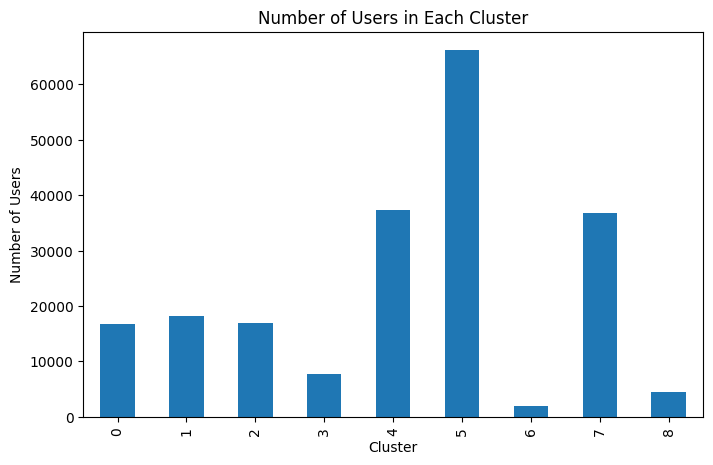

In [3]:
plt.figure(figsize=(8,5))

cluster_counts.plot(kind="bar")

plt.title("Number of Users in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Users")

plt.show()

In [4]:
behavior_summary = (
    segments.groupby("cluster")[
        [
            "total_orders",
            "avg_days_between_orders",
            "reorder_ratio"
        ]
    ]
    .mean()
)

behavior_summary

,total_orders,avg_days_between_orders,reorder_ratio
cluster,,,
0,13.341014,16.398684,0.497223
1,10.604647,17.204736,0.385879
2,10.249673,16.314896,0.375924
3,10.708382,18.436444,0.311165
4,9.004332,18.400446,0.279476
5,10.728818,16.764596,0.404529
6,13.005013,15.471045,0.366304
7,43.552590,7.878781,0.686543
8,16.845388,14.539127,0.420814


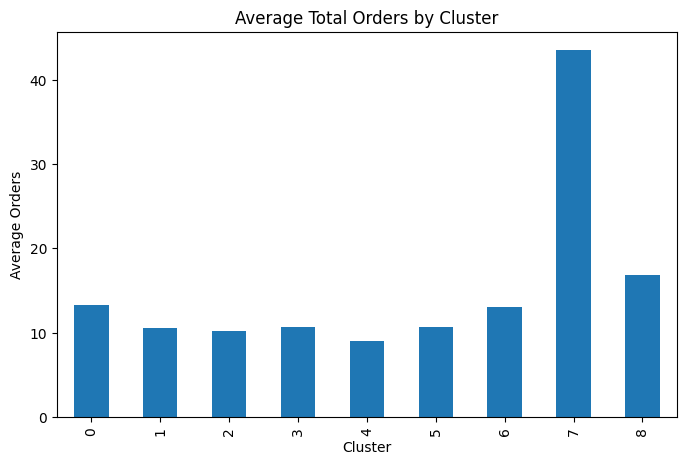

In [5]:
plt.figure(figsize=(8,5))

behavior_summary["total_orders"].plot(kind="bar")

plt.title("Average Total Orders by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Orders")

plt.show()

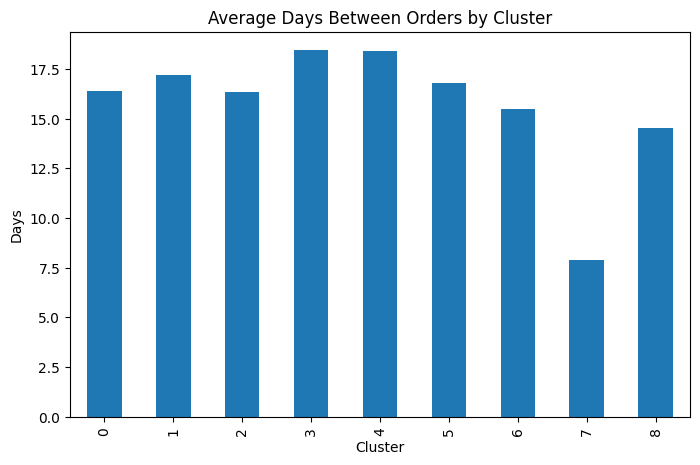

In [6]:
plt.figure(figsize=(8,5))

behavior_summary["avg_days_between_orders"].plot(kind="bar")

plt.title("Average Days Between Orders by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Days")

plt.show()

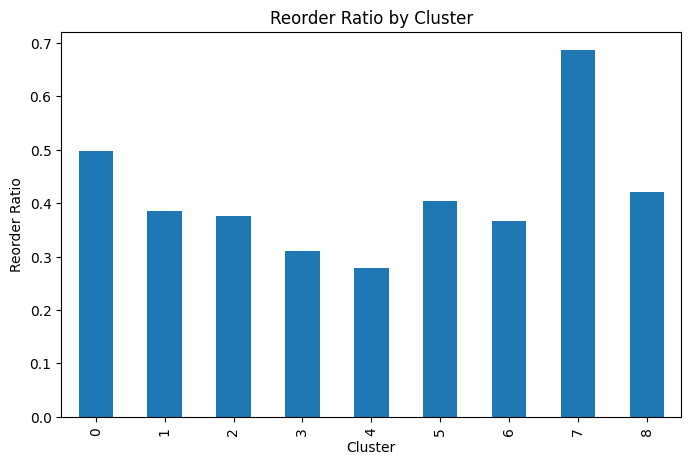

In [7]:
plt.figure(figsize=(8,5))

behavior_summary["reorder_ratio"].plot(kind="bar")

plt.title("Reorder Ratio by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Reorder Ratio")

plt.show()

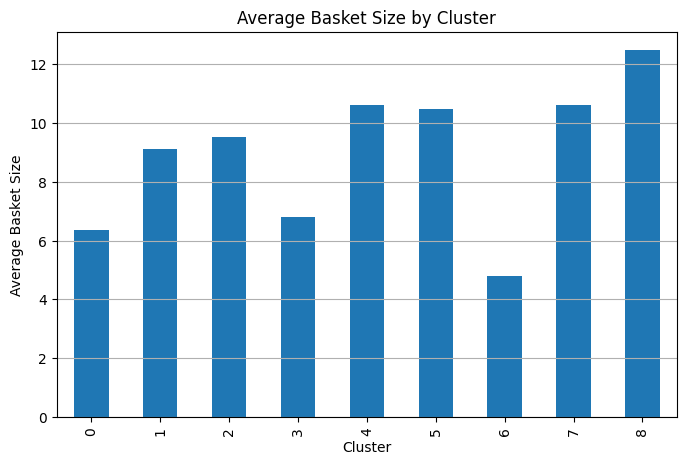

In [8]:
order_size = (
    analysis_table
    .groupby(["cluster", "order_id"])
    .size()
    .reset_index(name="basket_size")
)

cluster_basket_size = (
    order_size
    .groupby("cluster")["basket_size"]
    .mean()
)

plt.figure(figsize=(8,5))

cluster_basket_size.plot(kind="bar")

plt.title("Average Basket Size by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Basket Size")

plt.grid(axis="y")
plt.show()

In [9]:
department_columns = [
    'alcohol',
    'babies',
    'bakery',
    'beverages',
    'breakfast',
    'bulk',
    'canned goods',
    'deli',
    'dry goods pasta',
    'frozen',
    'household',
    'international',
    'meat seafood',
    'missing',
    'other',
    'pantry',
    'personal care',
    'pets',
    'snacks'
]

In [10]:
department_summary = (
    segments.groupby("cluster")[department_columns]
    .mean()
)

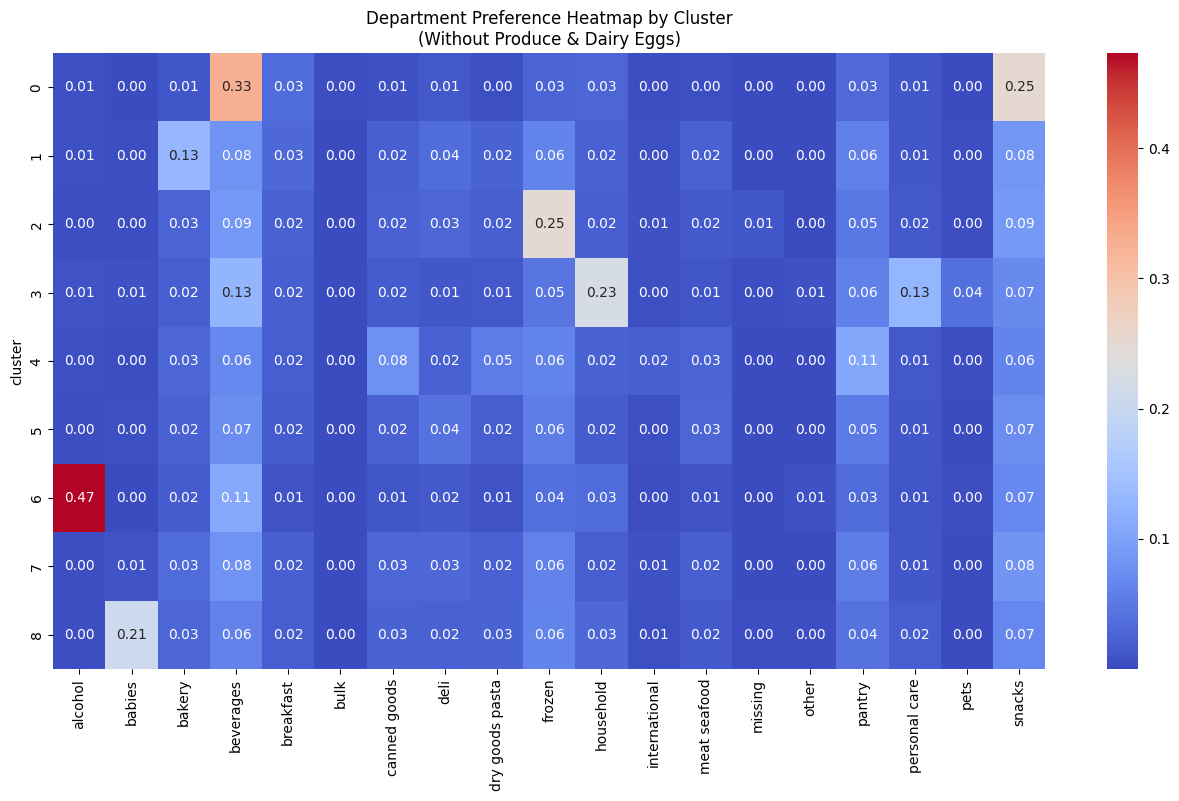

In [11]:
plt.figure(figsize=(16,8))

sns.heatmap(
    department_summary,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title(
    "Department Preference Heatmap by Cluster\n(Without Produce & Dairy Eggs)"
)

plt.show()

# Cluster Persona Summary

| Cluster | Persona |
|---|---|
| 0 | Beverage & Snack Users |
| 1 | Bakery-oriented Users |
| 2 | Frozen-food Users |
| 3 | Household & Personal Care Users |
| 6 | Alcohol-oriented Users |
| 8 | Baby-product Families |

In [12]:
filtered_analysis = analysis_table[
    ~analysis_table["department"].isin(
        ["produce", "dairy eggs"]
    )
]

In [13]:
top_products = (
    filtered_analysis
    .groupby(["cluster", "product_name"])
    .size()
    .reset_index(name="count")
)

In [14]:
top10_products = (
    top_products
    .sort_values(
        ["cluster", "count"],
        ascending=[True, False]
    )
    .groupby("cluster")
    .head(10)
)

top10_products.head(20)

,cluster,product_name,count
22499,0,Soda,15727
22845,0,Sparkling Water Grapefruit,10003
23142,0,Spring Water,7558
12763,0,Lime Sparkling Water,6836
22807,0,Sparkling Lemon Water,6075
24854,0,Trail Mix,5822
22810,0,Sparkling Mineral Water,5386
22813,0,Sparkling Natural Mineral Water,5165
26875,0,Zero Calorie Cola,4848
7803,0,Extra Fancy Unsalted Mixed Nuts,4554


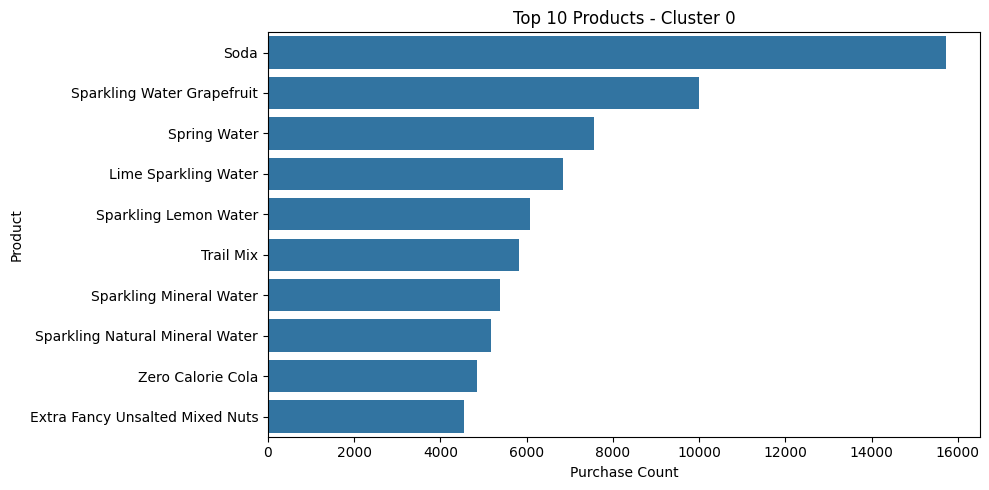

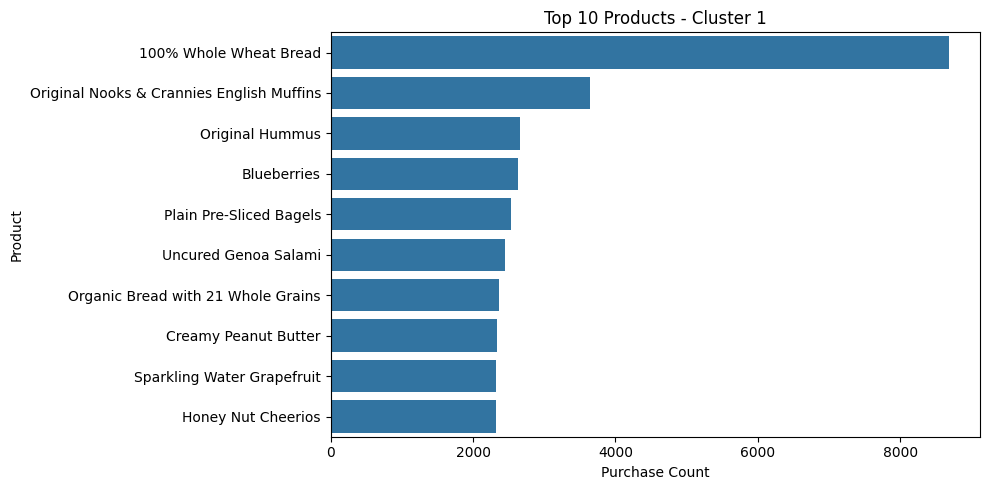

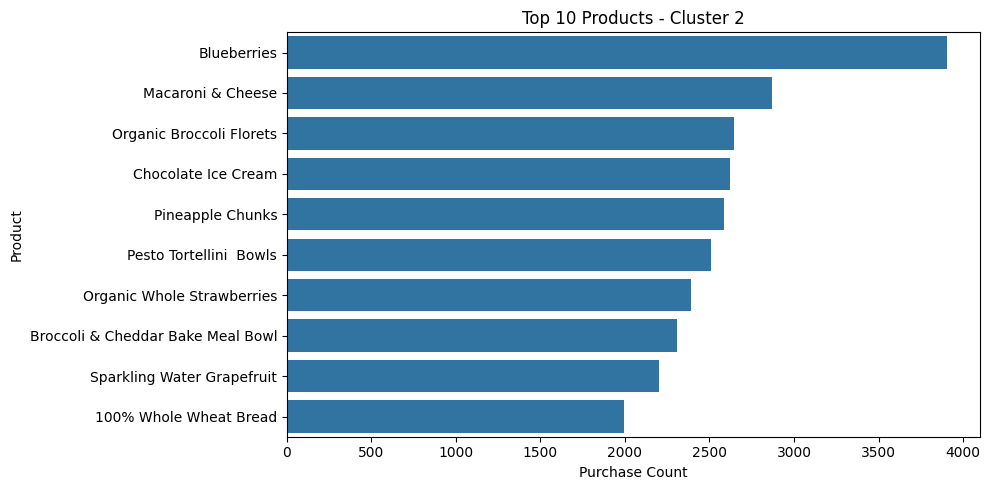

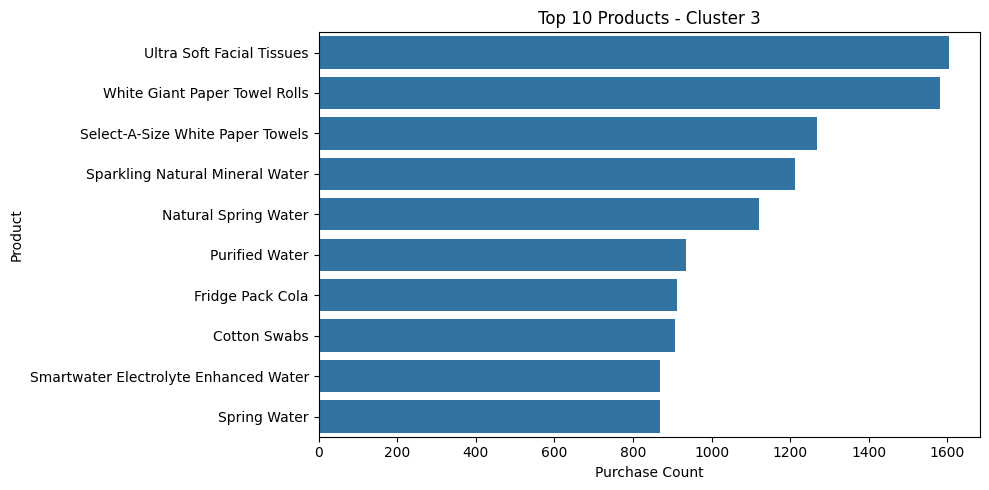

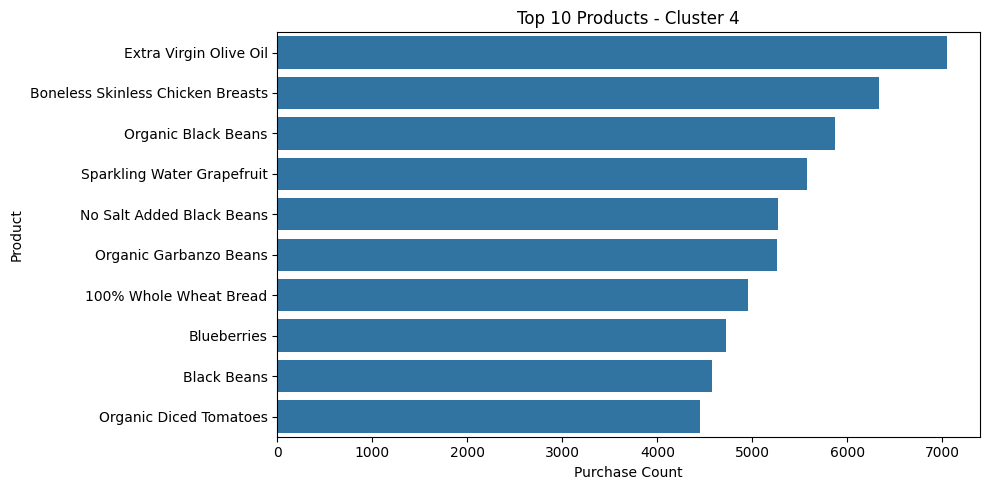

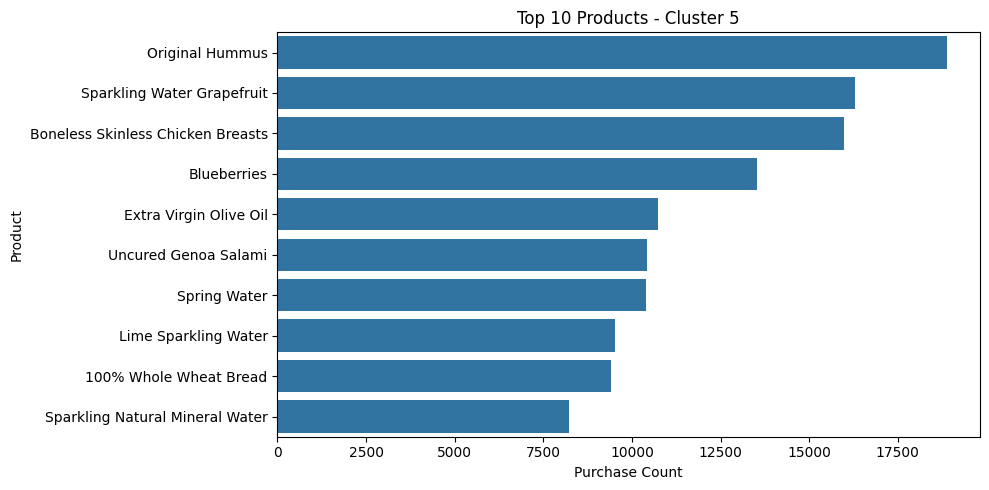

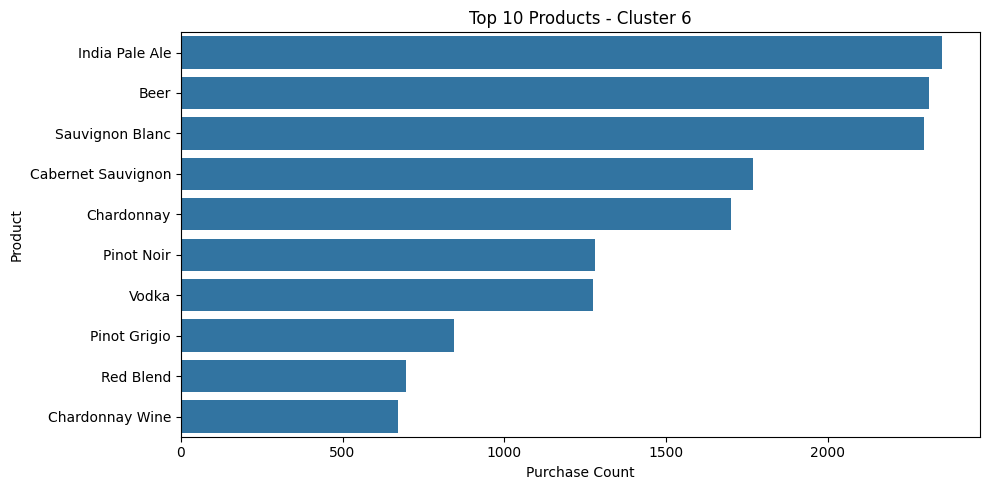

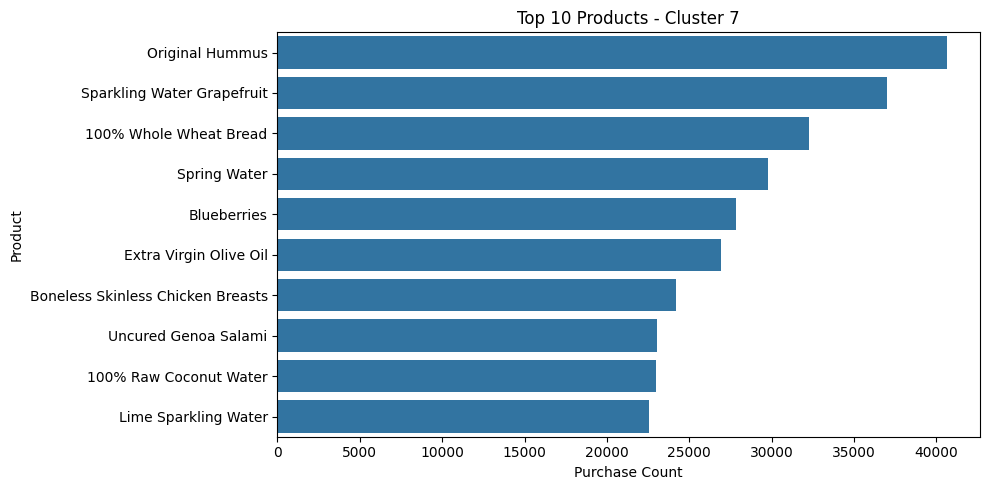

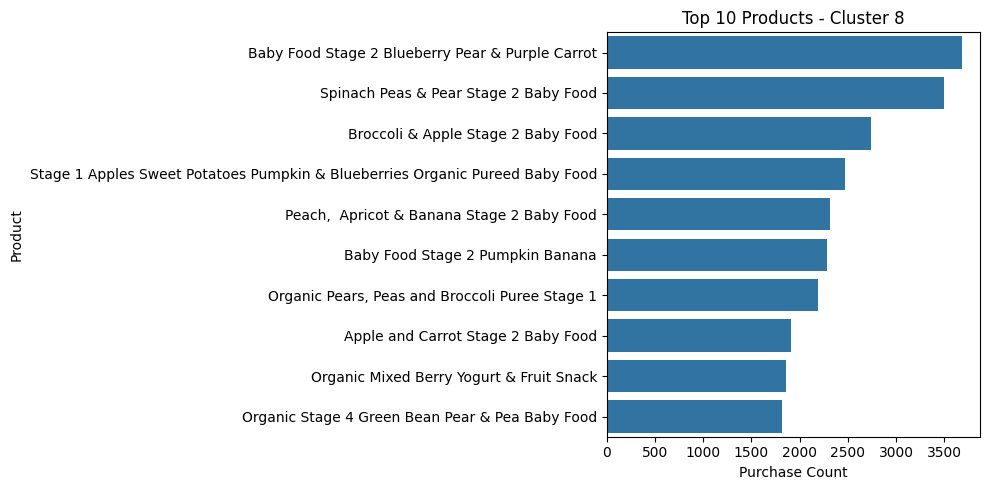

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

clusters = sorted(
    top10_products["cluster"].unique()
)

for c in clusters:

    plt.figure(figsize=(10, 5))

    cluster_data = top10_products[
        top10_products["cluster"] == c
    ].head(10)

    sns.barplot(
        data=cluster_data,
        x="count",
        y="product_name"
    )

    plt.title(f"Top 10 Products - Cluster {c}")
    plt.xlabel("Purchase Count")
    plt.ylabel("Product")

    plt.tight_layout()
    plt.show()

In [16]:
cluster_hour = (
    analysis_table
    .groupby("cluster")["order_hour_of_day"]
    .mean()
)

cluster_hour

cluster
0    12.690539
1    13.536922
2    13.842817
3    13.554888
4    13.671880
5    13.640847
6    13.288321
7    13.299479
8    13.383158
Name: order_hour_of_day, dtype: float64

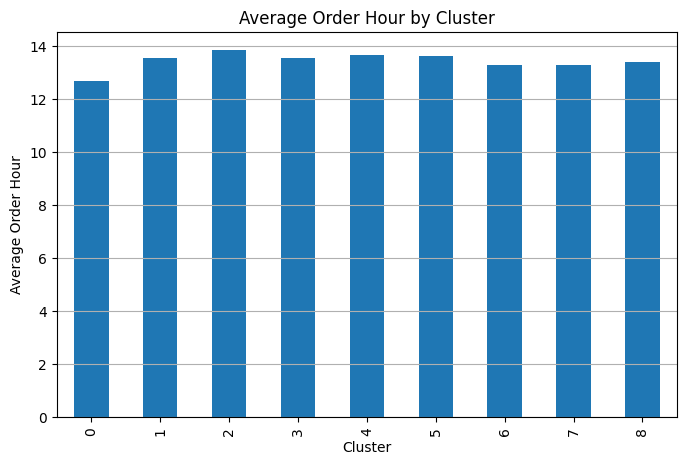

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

cluster_hour.plot(kind="bar")

plt.title("Average Order Hour by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Order Hour")

plt.grid(axis="y")

plt.show()

In [18]:
hour_distribution = (
    analysis_table
    .groupby(["cluster", "order_hour_of_day"])
    .size()
    .reset_index(name="count")
)

hour_distribution.head()

,cluster,order_hour_of_day,count
0,0,0,6534
1,0,1,3980
2,0,2,2805
3,0,3,1607
4,0,4,1666


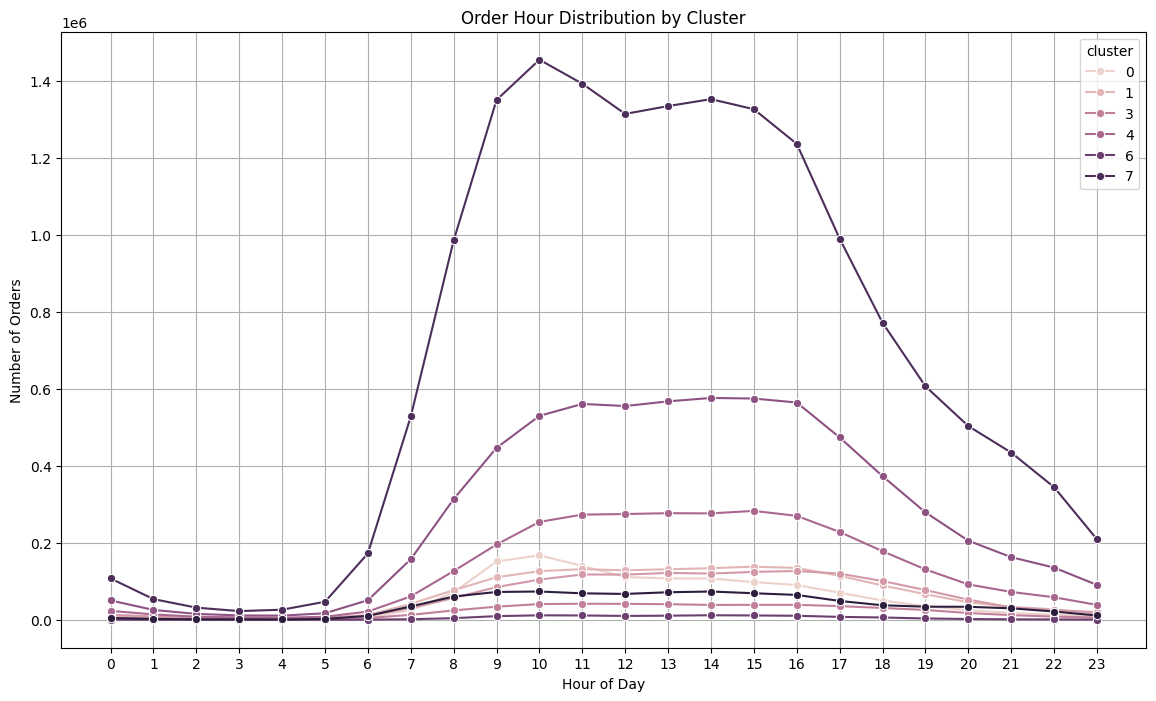

In [22]:
import seaborn as sns

plt.figure(figsize=(14,8))

sns.lineplot(
    data=hour_distribution,
    x="order_hour_of_day",
    y="count",
    hue="cluster",
    marker="o"
)

plt.title("Order Hour Distribution by Cluster")

plt.xlabel("Hour of Day")
plt.ylabel("Number of Orders")

plt.xticks(range(0,24))

plt.grid(True)

plt.show()

In [32]:
target_cluster = 0

cluster_data = analysis_table[
    analysis_table["cluster"] == target_cluster
].copy()

# 移除 produce / dairy eggs
cluster_data = cluster_data[
    ~cluster_data["department"].isin(["produce", "dairy eggs"])
]

# 只保留該 cluster 最常出現的前 100 個商品
top_products = (
    cluster_data["product_name"]
    .value_counts()
    .head(100)
    .index
)

cluster_data = cluster_data[
    cluster_data["product_name"].isin(top_products)
]

basket = (
    cluster_data
    .groupby(["order_id", "product_name"])
    .size()
    .unstack(fill_value=0)
)

basket = (basket > 0).astype(int)

basket.shape


from mlxtend.frequent_patterns import apriori, association_rules

frequent_items = apriori(
    basket,
    min_support=0.01,
    use_colnames=True
)

rules = association_rules(
    frequent_items,
    metric="lift",
    min_threshold=1.0
)

rules = rules.sort_values(
    by="lift",
    ascending=False
)

rules.head(20)

d:\CCU\Courese\大四下\機器學習\FinalProject\Final Project\.venv\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({Lemon Sparkling Water}),frozenset({Grapefruit Sparkling Water}),0.021140,0.028048,0.010972,0.519039,18.505202,1.0,0.010379,2.020853,0.966390,0.287117,0.505159,0.455117
1,frozenset({Grapefruit Sparkling Water}),frozenset({Lemon Sparkling Water}),0.028048,0.021140,0.010972,0.391195,18.505202,1.0,0.010379,1.607840,0.973259,0.287117,0.378047,0.455117
14,frozenset({Peach Pear Flavored Sparkling Water}),frozenset({Sparkling Water Berry}),0.030104,0.028900,0.010441,0.346833,12.001091,1.0,0.009571,1.486755,0.945126,0.214998,0.327394,0.354055
15,frozenset({Sparkling Water Berry}),frozenset({Peach Pear Flavored Sparkling Water}),0.028900,0.030104,0.010441,0.361276,12.001091,1.0,0.009571,1.518491,0.943955,0.214998,0.341452,0.354055
36,frozenset({Lime Sparkling Water}),"frozenset({Sparkling Lemon Water, Sparkling Wa...",0.053424,0.024868,0.014575,0.272820,10.970945,1.0,0.013247,1.340979,0.960145,0.228750,0.254276,0.429465
33,"frozenset({Sparkling Lemon Water, Sparkling Wa...",frozenset({Lime Sparkling Water}),0.024868,0.053424,0.014575,0.586109,10.970945,1.0,0.013247,2.287020,0.932027,0.228750,0.562750,0.429465
35,frozenset({Sparkling Lemon Water}),"frozenset({Lime Sparkling Water, Sparkling Wat...",0.047477,0.029314,0.014575,0.306996,10.472562,1.0,0.013183,1.400693,0.949596,0.234267,0.286067,0.402098
34,"frozenset({Lime Sparkling Water, Sparkling Wat...",frozenset({Sparkling Lemon Water}),0.029314,0.047477,0.014575,0.497201,10.472562,1.0,0.013183,1.894441,0.931828,0.234267,0.472140,0.402098
27,frozenset({Sparkling Water Berry}),frozenset({Sparkling Lemon Water}),0.028900,0.047477,0.012551,0.434289,9.147445,1.0,0.011179,1.683763,0.917187,0.196645,0.406092,0.349325
26,frozenset({Sparkling Lemon Water}),frozenset({Sparkling Water Berry}),0.047477,0.028900,0.012551,0.264362,9.147445,1.0,0.011179,1.320079,0.935074,0.196645,0.242469,0.349325


In [24]:
import os
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# 建立儲存資料夾
OUTPUT_DIR = "../data/processed/association_rules"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 每個 cluster 使用不同 support
support_map = {
    0: 0.01,
    1: 0.005,
    2: 0.003,
    3: 0.005,
    4: 0.005,
    5: 0.005,
    6: 0.003,
    7: 0.005,
    8: 0.003
}

clusters = sorted(analysis_table["cluster"].dropna().unique())

for c in clusters:
    print(f"\nProcessing Cluster {c}")

    cluster_data = analysis_table[
        analysis_table["cluster"] == c
    ].copy()

    cluster_data = cluster_data[
        ~cluster_data["department"].isin(["produce", "dairy eggs"])
    ]

    top_products = (
        cluster_data["product_name"]
        .value_counts()
        .head(100)
        .index
    )

    cluster_data = cluster_data[
        cluster_data["product_name"].isin(top_products)
    ]

    basket = (
        cluster_data
        .groupby(["order_id", "product_name"])
        .size()
        .unstack(fill_value=0)
    )

    basket = (basket > 0).astype(int)

    min_support = support_map.get(c, 0.005)

    frequent_items = apriori(
        basket,
        min_support=min_support,
        use_colnames=True
    )

    if frequent_items.empty:
        print(f"Cluster {c}: no frequent itemsets")
        continue

    rules = association_rules(
        frequent_items,
        metric="lift",
        min_threshold=1.0
    )

    if rules.empty:
        print(f"Cluster {c}: no rules")
        continue

    rules = rules.sort_values(
        by="lift",
        ascending=False
    )

    rules.to_csv(
        f"{OUTPUT_DIR}/cluster_{c}_rules.csv",
        index=False
    )

    print(f"Cluster {c} saved. Rules: {len(rules)}")


Processing Cluster 0


d:\CCU\Courese\大四下\機器學習\FinalProject\Final Project\.venv\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


PermissionError: [Errno 13] Permission denied: '../data/processed/association_rules/cluster_0_rules.csv'

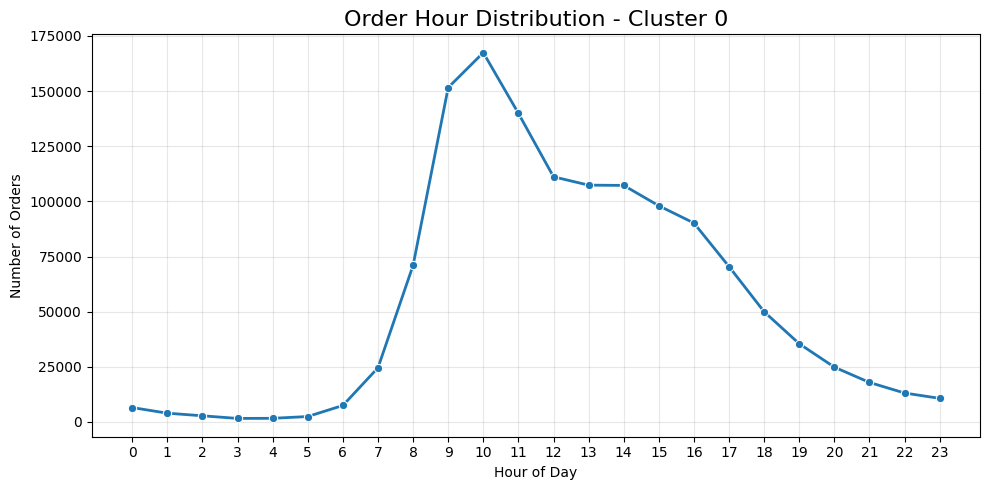

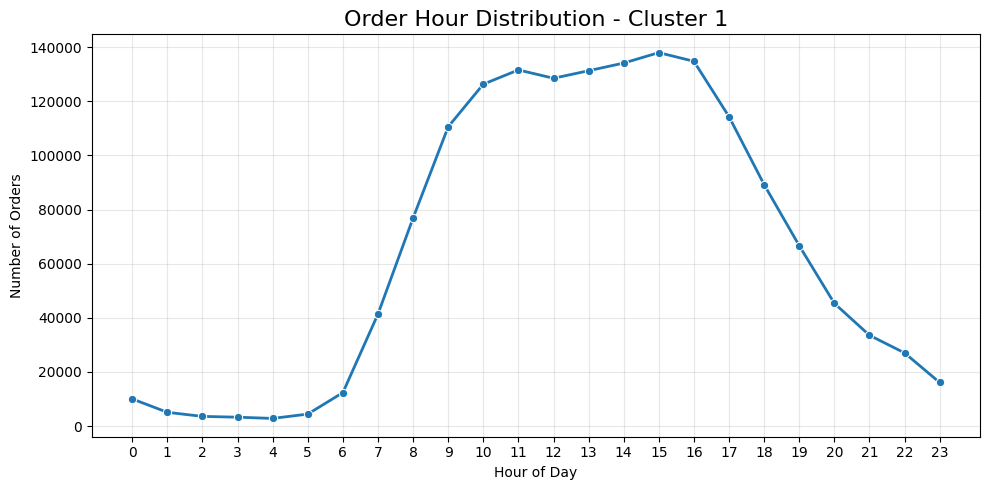

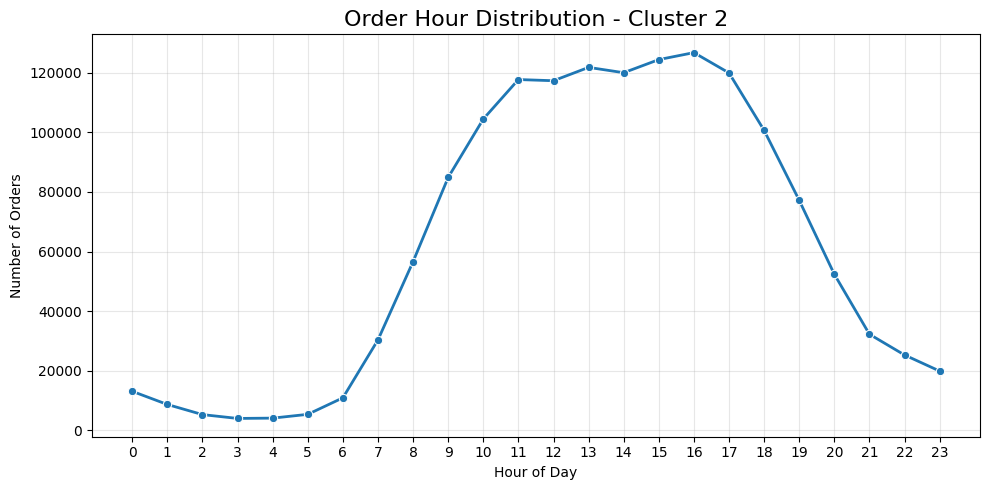

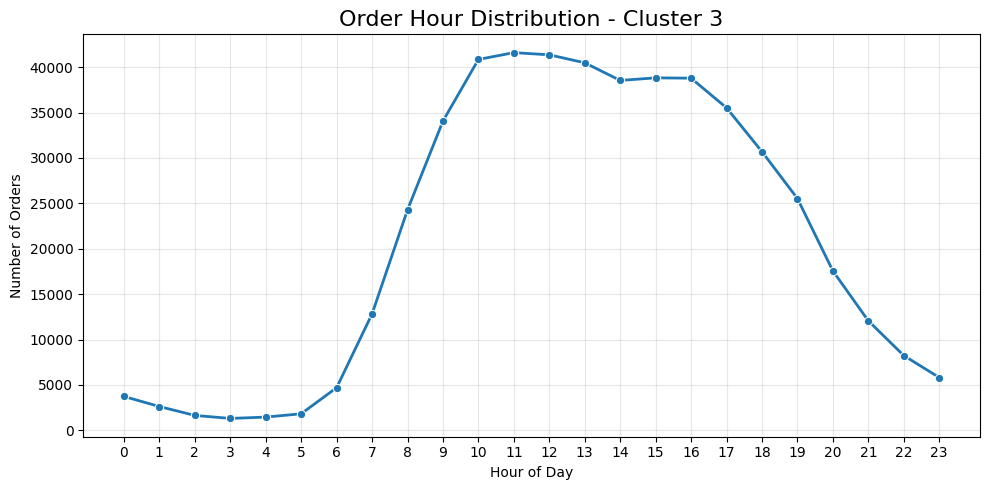

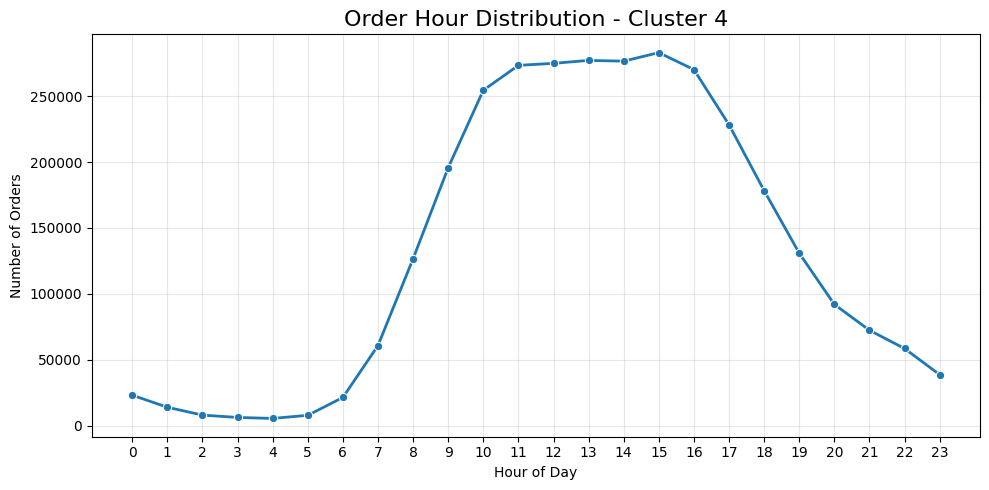

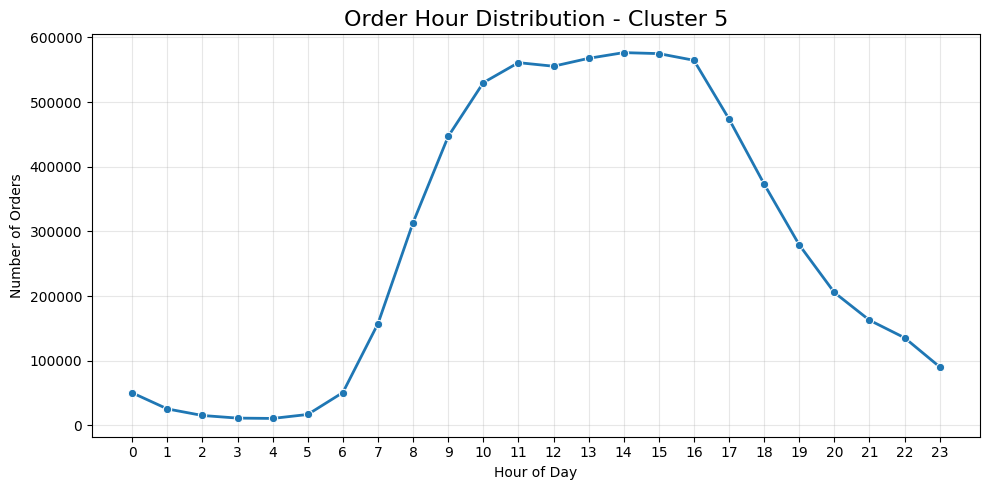

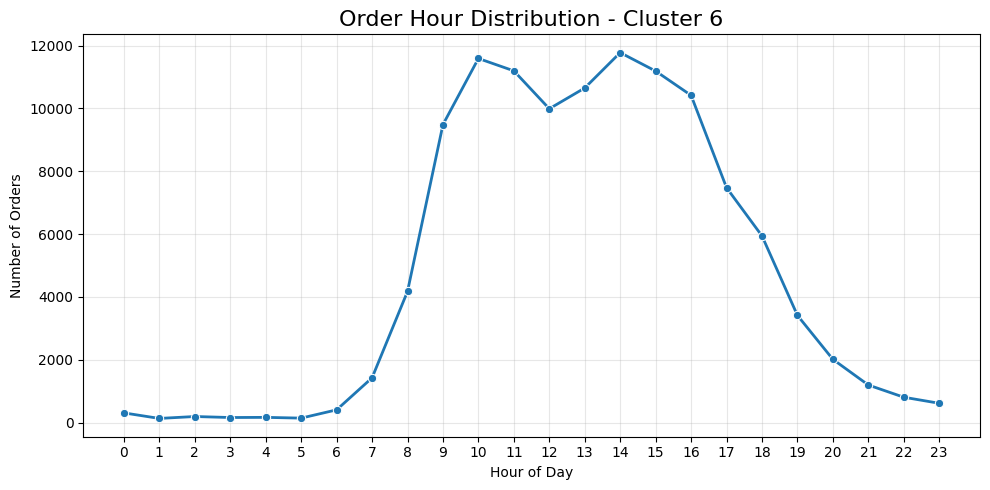

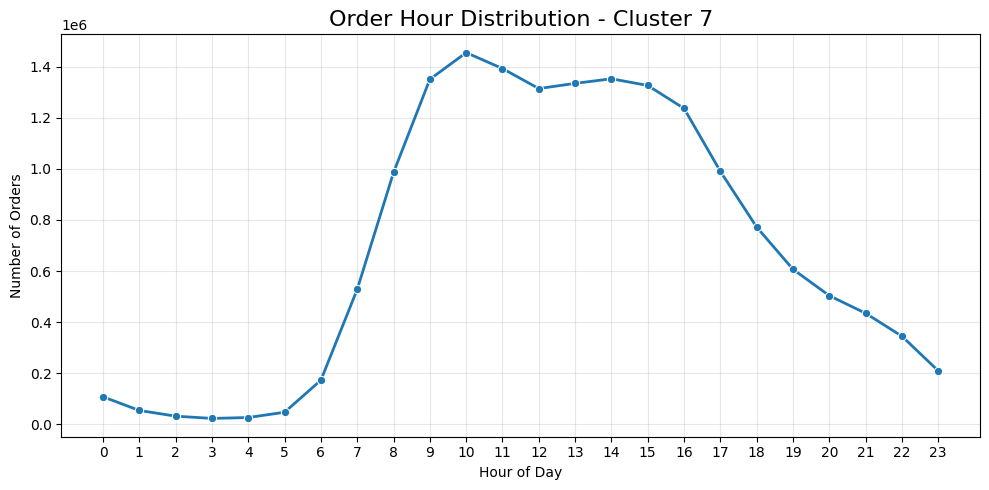

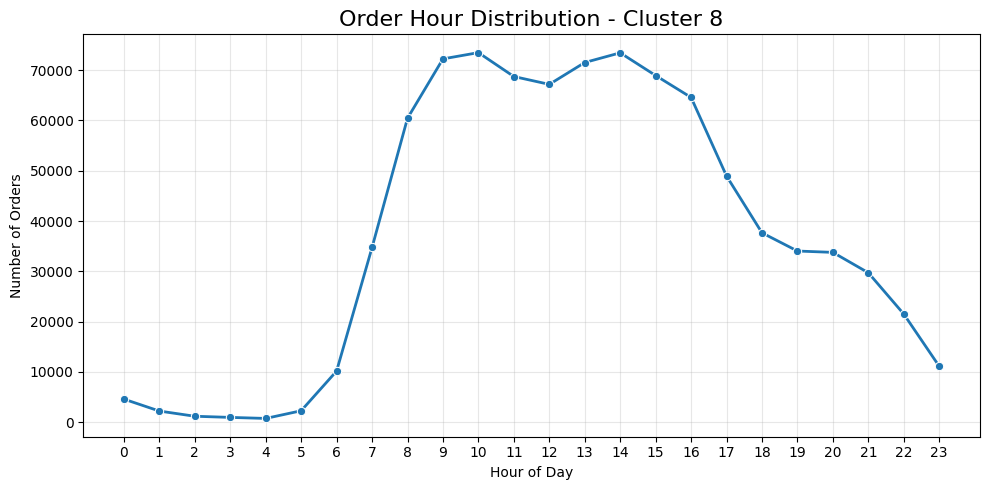

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# 統計每個 cluster 每小時訂單量
hour_cluster = (
    analysis_table
    .groupby(
        ["cluster", "order_hour_of_day"]
    )
    .size()
    .reset_index(name="count")
)

clusters = sorted(
    analysis_table["cluster"].unique()
)

# 每個 cluster 畫一張
for c in clusters:

    plt.figure(figsize=(10, 5))

    cluster_data = hour_cluster[
        hour_cluster["cluster"] == c
    ]

    sns.lineplot(
        data=cluster_data,
        x="order_hour_of_day",
        y="count",
        marker="o",
        linewidth=2
    )

    plt.title(
        f"Order Hour Distribution - Cluster {c}",
        fontsize=16
    )

    plt.xlabel("Hour of Day")
    plt.ylabel("Number of Orders")

    plt.xticks(range(24))

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.show()